# Trial1: analysis to refined full-sequence adaptation

One entry point for all **417 native frames (0–416, 30 FPS)**: verify the source
observations, inspect contacts and ground evidence, fit complete trajectories, and compare
support optimization, conditional ground support and convergence refinement.

Use **Python (Beta Translator)** / the repository `.venv/bin/python`. Set the target body
once in Section 1, then **Restart Kernel and Run All**. Verified outputs are reused only
when inputs, settings, code provenance and artifact hashes match. Otherwise new run
directories are created; a first run after code changes can take several minutes.

[Beta_Translator.ipynb](Beta_Translator.ipynb) remains the separate manual-review,
static/single-move workflow. This notebook reads its saved Trial1 inputs without executing
or modifying that notebook, its annotations or predictions. The 165 cm body in the saved
H44 → H28 example is not a measurement of the source climber.

The former standalone workflows are now included here: support optimization in Section 5,
ground evidence and adaptation in Sections 6–7, and convergence refinement in Section 8.
All historical videos and result directories remain available.

## 1. Setup & Target Body

Change height, proportions and physics assumptions here. The default demonstration uses
**180 cm, assumed 70 kg, and assumed friction 0.8**. Source-climber height and mass are
unknown. All stages share these settings. The refinement solver has its own convergence
controls; the older optimizer's round/evaluation limits do not control refinement.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import Image, Video, Markdown, display
from beta_translator.inverse_kinematics import RATIOS, make_body, make_mass_model
from beta_translator.trial1_sequence import load_inputs, TRIAL1_SCALE
from beta_translator.ground_support import load_ground_inputs
from beta_translator.trial1_support_pipeline import run_trial1_support_optimization
from beta_translator.trial1_ground_pipeline import run_trial1_ground_optimization
from beta_translator.trial1_refinement_pipeline import run_trial1_refinement
from beta_translator.support_optimization import DEFAULT_OPTIMIZATION_SETTINGS
from beta_translator.support_refinement import DEFAULT_REFINEMENT
from beta_translator.project_io import file_sha256

PROJECT_DIR = Path.cwd().resolve()
if not (PROJECT_DIR / 'beta_translator').is_dir():
    raise FileNotFoundError('Open this notebook from the Beta_Translator repository.')
VIDEO_FILE = PROJECT_DIR / 'videos/trial1.mp4'
TARGET_HEIGHT_CM = 180
TARGET_MASS_KG = 70.0  # Assumed; replace with the target user's measured mass if known.
TARGET_RATIOS = dict(RATIOS)
FOOT_FRICTION = 0.8  # Assumed for floor and foot-on-hold contacts.
MAX_FORCE_N = None  # None means one body weight per contact-force component.
GRAVITY_SETTINGS = {}
AUDIT_SETTINGS = dict(com_perturbation_cm=2.0, margin_warning=0.1, unload_lookahead_frames=6)
OPTIMIZATION_SETTINGS = dict(DEFAULT_OPTIMIZATION_SETTINGS)
REFINEMENT_SETTINGS = dict(DEFAULT_REFINEMENT)
make_body(TARGET_HEIGHT_CM, TARGET_RATIOS)
make_mass_model(TARGET_MASS_KG)
COMMON_SETTINGS = dict(height_cm=TARGET_HEIGHT_CM, ratios=TARGET_RATIOS,
    mass_kg=TARGET_MASS_KG, foot_friction=FOOT_FRICTION, max_force_n=MAX_FORCE_N,
    settings=GRAVITY_SETTINGS, audit_config=AUDIT_SETTINGS, optimization=OPTIMIZATION_SETTINGS)
print(f'Target: {TARGET_HEIGHT_CM:g} cm | assumed mass: {TARGET_MASS_KG:g} kg')
print('Source climber height/mass: unknown. Uniform-scale 2D model; no Trial3 plane calibration.')

def show_video(path, width=900):
    path = Path(path).resolve()
    if not path.is_file():
        raise FileNotFoundError(f'Missing video: {path}. Restore Git LFS assets or rerun its stage.')
    display(Video(url=path.relative_to(PROJECT_DIR).as_posix(), embed=False, width=width))

def show_counts(values):
    display(pd.DataFrame(list(values.items()), columns=['status / issue', 'count']))

def show_review(result, label):
    path = Path(result['output_dir']) / result['review_page']
    if not path.is_file():
        raise FileNotFoundError(path)
    display(Markdown(f'[{label}]({path.relative_to(PROJECT_DIR).as_posix()})'))

progress = lambda message: print(message, flush=True)

Target: 180 cm | assumed mass: 70 kg
Source climber height/mass: unknown. Uniform-scale 2D model; no Trial3 plane calibration.


## 2. Source Video & Verified Inputs

Read the bundled source video and existing pose, alignment, hold-map and contact-model
outputs. The loader verifies their provenance and requires an observed pose and valid
alignment for every native frame. Missing observations are not silently interpolated.
The video below is the **original filmed climber**, independent of the target height.

This entry point reuses the saved analysis inputs. It does not retrain the contact model,
rerun the manual review UI or rebuild the hold map.

In [2]:
inputs = load_inputs(PROJECT_DIR)
np.testing.assert_array_equal(inputs['schedule']['frames'], np.arange(417))
assert inputs['fps'] == 30
display(pd.DataFrame([{
    'frames': len(inputs['schedule']['frames']), 'first_frame': 0, 'last_frame': 416,
    'fps': inputs['fps'], 'duration_seconds': len(inputs['schedule']['frames']) / inputs['fps'],
    'reference_frame': inputs['geometry']['reference_frame_number'],
    'hold_candidates': len(inputs['records']), 'selected_holds': len(inputs['selected']),
}]))
print('ORIGINAL CLIMBER — source video')
show_video(VIDEO_FILE, width=500)

,frames,first_frame,last_frame,fps,duration_seconds,reference_frame,hold_candidates,selected_holds
0,417,0,416,30.0,13.9,0,65,21


ORIGINAL CLIMBER — source video


## 3. Hold Map & Geometry Assumptions

Trial1 uses its existing **46 cm reference-image distance**: `hypot(80, -21) / 46`,
about 1.798 pixels/cm. The target height does not set this scale. Reference-image up
is assumed to oppose gravity. This uniform-scale model does not rectify perspective
or recover wall angle, camera roll, floor depth or body depth.

All frames retain geometry-uncertainty flags. Reached/confident/mapped support is
eligible only under this approximation, not independently calibrated physical support.

Pixels/cm: 1.7980508245001927
Geometry: 46 cm measured image gap; uniform scale, image-up gravity assumed
Selected holds: H65, H64, H63, H60, H57, H51, H53, H45, H40, H48, H44, H38, H34, H33, H28, H26, H23, H17, H16, H13, H62


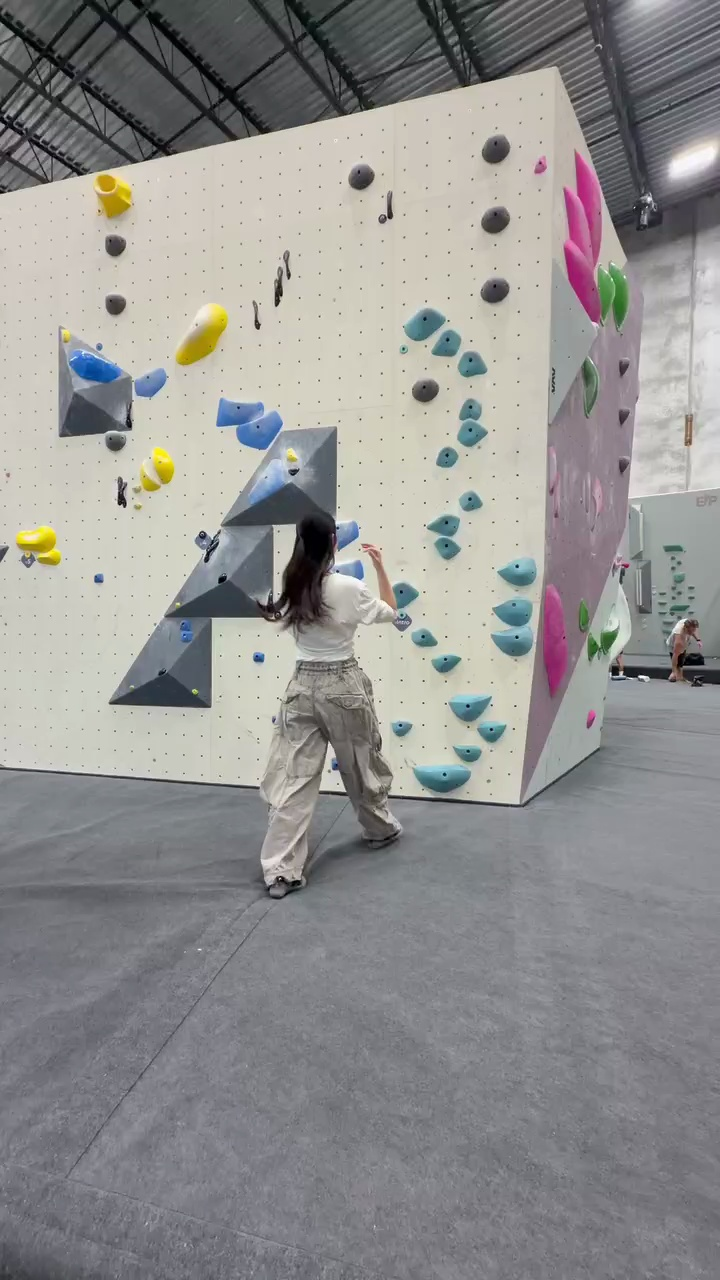

,hold_id,cx_px,cy_px
12,H13,423.788571,322.913143
15,H16,446.898551,342.960145
16,H17,471.437269,363.619926
22,H23,470.323834,409.064767
25,H26,470.695413,431.607339
27,H28,446.947674,456.590116
32,H33,469.750000,499.980769
33,H34,444.762000,524.162000
37,H38,447.018182,546.849351
39,H40,519.648196,570.618557


In [3]:
print('Pixels/cm:', TRIAL1_SCALE)
print('Geometry:', inputs['geometry']['scale_source'])
print('Selected holds:', ', '.join(inputs['selected']))
display(Image(filename=str(PROJECT_DIR / 'outputs/images/wall_reference.jpg'), width=600))
hold_table = pd.DataFrame(inputs['records'])
display(hold_table[hold_table.hold_id.isin(inputs['selected'])][['hold_id', 'cx_px', 'cy_px']])

## 4. Automatic Contacts & Reviewed Reference

Decoded per-frame contacts and release/arrival times supply the full-sequence model.
The saved human-confirmed **H44 → H28, frames 107–129** example is a separate disagreement
check. Its 92 reviewed limb/frame labels are not copied into automatic optimization targets.
Model acceptance/coverage is not contact accuracy or a probability of climbing success.

In [4]:
prediction = inputs['prediction']
move_columns = ['moving_limb', 'from_hold', 'to_hold', 'before_frame', 'release_frame', 'arrival_frame', 'after_frame']
display(pd.DataFrame(prediction['moves']).reindex(columns=move_columns))
reviewed_reference = inputs['reference_comparison']
print('Saved reviewed comparisons:', len(reviewed_reference),
      '| disagreement frames:', reviewed_reference.loc[~reviewed_reference.agrees, 'frame'].nunique())
display(reviewed_reference.loc[~reviewed_reference.agrees])
print('Automatic labels are preserved. A free foot does not establish ground contact.')

,moving_limb,from_hold,to_hold,before_frame,release_frame,arrival_frame,after_frame
0,left_hand,H44,H28,105,113,136,143
1,left_hand,H28,H26,233,241,241,248
2,left_hand,H26,H16,280,288,305,312
3,right_hand,H44,H33,68,76,103,110
4,right_hand,H33,H26,203,211,226,233
5,right_hand,H26,H23,275,283,283,290
6,right_hand,H23,H17,300,308,327,334
7,left_foot,H62,H51,172,180,206,213
8,right_foot,H65,H60,145,153,173,180
9,right_foot,H60,H45,258,266,286,293


Saved reviewed comparisons: 92 | disagreement frames: 6


,frame,limb,reviewed_contact,predicted_contact,confidence,agrees,evidence
24,113,left_hand,H44,free,0.557964,False,Saved user-confirmed H44-H28 reference; no lab...
28,114,left_hand,H44,free,0.780893,False,Saved user-confirmed H44-H28 reference; no lab...
32,115,left_hand,H44,free,0.918093,False,Saved user-confirmed H44-H28 reference; no lab...
36,116,left_hand,H44,free,0.960024,False,Saved user-confirmed H44-H28 reference; no lab...
84,128,left_hand,H28,free,0.936262,False,Saved user-confirmed H44-H28 reference; no lab...
88,129,left_hand,H28,free,0.845838,False,Saved user-confirmed H44-H28 reference; no lab...


Automatic labels are preserved. A free foot does not establish ground contact.


## 5. Gravity Baseline & Support Optimization

First fit gravity IK, then optimize contact validity, support reserve, pre-release unloading
and temporal motion across all 417 frames. This version grants no ground support to free
feet. Both videos use the configured fixed-length target body.

Red indicates a failed constraint, amber indicates uncertainty or low reserve. All input
uncertainty remains visible. A finite trajectory may be exported after an iteration limit;
the optimizer status and failure flags must still be read. Fixed IRLS rounds are not an
outer-convergence test. See [the support optimization method](docs/trial1_support_optimization.md).

In [5]:
support_run = run_trial1_support_optimization(PROJECT_DIR, **COMMON_SETTINGS, progress=progress)
SUPPORT_RUN_DIR = Path(support_run['output_dir'])
print('No-ground support optimization:', SUPPORT_RUN_DIR.relative_to(PROJECT_DIR))
print('Final optimizer:', support_run['optimizer'])
print('GRAVITY BASELINE — no ground support')
show_video(SUPPORT_RUN_DIR / support_run['baseline_video_name'])
print('SUPPORT-OPTIMIZED TARGET — no ground support')
show_video(support_run['video_file'])
display(pd.read_csv(SUPPORT_RUN_DIR / 'comparison.csv'))
show_counts(support_run['balance_audit_counts'])
show_review(support_run, 'Open synchronized source / gravity / support-optimized review')

Reused verified Trial1 support-optimized full sequence.


No-ground support optimization: outputs/trial1/support_optimized/target_180cm_b55939aa0a8b
Final optimizer: {'success': False, 'message': 'The maximum number of function evaluations is exceeded.', 'nfev': 800, 'cost': 664.0155194110476, 'optimality': 167.42206062327918}
GRAVITY BASELINE — no ground support


SUPPORT-OPTIMIZED TARGET — no ground support


,metric,unit,before,after
0,contact_residual,frames,106.000000,1.000000
1,large_contact_residual,frames,1.000000,0.000000
2,support_balance_failed,frames,75.000000,49.000000
3,support_balance_uncertain,frames,59.000000,65.000000
4,support_margin_low,frames,31.000000,0.000000
5,preunload_failed,frames,19.000000,0.000000
6,preunload_uncertain,frames,13.000000,28.000000
7,preunload_margin_low,frames,0.000000,0.000000
8,departing_load_remaining,frames,11.000000,0.000000
9,rapid_pose_change,frames,0.000000,0.000000


,status / issue,count
0,fails_located_support_model,49
1,uncertain_support,65
2,passes_model_checks,303


[Open synchronized source / gravity / support-optimized review](outputs/trial1/support_optimized/target_180cm_b55939aa0a8b/review.html)

## 6. Ground Support Evidence & Assumptions

The current ground model uses manually estimated floor image polygons and assistant
visual interval assessment in `data/trial1_ground_support.json`; it is **not user-confirmed
ground truth or automatic wall/floor segmentation**. Visible heel/toe observations are
also required. Unreviewed or ambiguous candidates get no ground force.

The source sole is an approximate lower heel/toe point. The target sole is assumed to be
2.5% of height below the ankle (4.5 cm at 180 cm). Ground support stays conditional because
floor geometry, image-up normal and friction are assumed. Raw labels/confidence remain
unchanged; separate support IDs describe the added contact model. A support observation
ending does not necessarily identify the true liftoff frame.

In [6]:
ground_inputs = load_ground_inputs(PROJECT_DIR, inputs, TARGET_HEIGHT_CM)
ground_annotation = ground_inputs['ground_annotation']
ground_rows = pd.DataFrame(ground_inputs['ground_rows'])
np.testing.assert_array_equal(inputs['schedule']['labels'], ground_inputs['schedule']['labels'])
np.testing.assert_array_equal(inputs['schedule']['confidence'], ground_inputs['schedule']['confidence'])
print('Ground evidence reviewer:', ground_annotation['reviewer'])
print('User confirmed:', ground_annotation['user_confirmed'])
print('Assumed sole offset:', TARGET_HEIGHT_CM * ground_annotation['sole_offset_height_ratio'], 'cm')
display(pd.crosstab(ground_rows['limb'], ground_rows['state']))
ground_intervals = pd.DataFrame([
    {'limb': limb, **interval} for limb, intervals in ground_annotation['intervals'].items()
    for interval in intervals])
display(ground_intervals)
print('Effective ground limb-frames:', int((ground_inputs['schedule']['contact_type'] == 'ground').sum()))
print('Ground candidates are proposals only; unreviewed free limbs are never grounded by default.')

Ground evidence reviewer: assistant_visual_review
User confirmed: False
Assumed sole offset: 4.5 cm


state,ground_candidate,observed_ground,off_ground,unknown
limb,,,,
left_foot,1,30,15,371
right_foot,0,18,42,357


,limb,start,end,state,support_id,note
0,left_foot,0,2,observed_ground,ground_left_001,Visible shoe-floor contact; frames 3-5 are a r...
1,left_foot,6,12,off_ground,NaN,Visible swing foot; no ground force.
2,left_foot,29,62,observed_ground,ground_left_002,Visible planted toe/shoe near wall while right...
3,left_foot,67,74,off_ground,NaN,Left shoe clearly separated from floor; wall/h...
4,right_foot,0,20,observed_ground,ground_right_001,Visible floor contact during approach. Frames ...
5,right_foot,33,74,off_ground,NaN,Foot above floor / moving onto wall hold; this...


Effective ground limb-frames: 48
Ground candidates are proposals only; unreviewed free limbs are never grounded by default.


## 7. Ground-Aware Full Sequence

A fresh gravity initialization includes the same conditional ground evidence from the
start, followed by coupled support optimization. Ground supports use sole contact points
for contact gaps, force moments and unloading. All 417 frames remain jointly fitted.

The before/after table here compares **fresh gravity and optimized poses with the same
ground evidence**. `published_comparison.csv` instead compares this model with the saved
180 cm no-ground result, so it changes support evidence and may also change body settings.
The review page's previous video is always that labeled historical 180 cm run, not necessarily
the current Section 5 output. See [ground assumptions](docs/trial1_ground_support.md).

Reused verified Trial1 ground-support full sequence.


Ground-support run: outputs/trial1/ground_support/target_180cm_98e558876cb0
Final optimizer: {'success': False, 'message': 'The maximum number of function evaluations is exceeded.', 'nfev': 800, 'cost': 637.9997793904038, 'optimality': 285.71998049294}
Conditional ground limb-frames: 48 | geometrically eligible ground limb-frames: 0


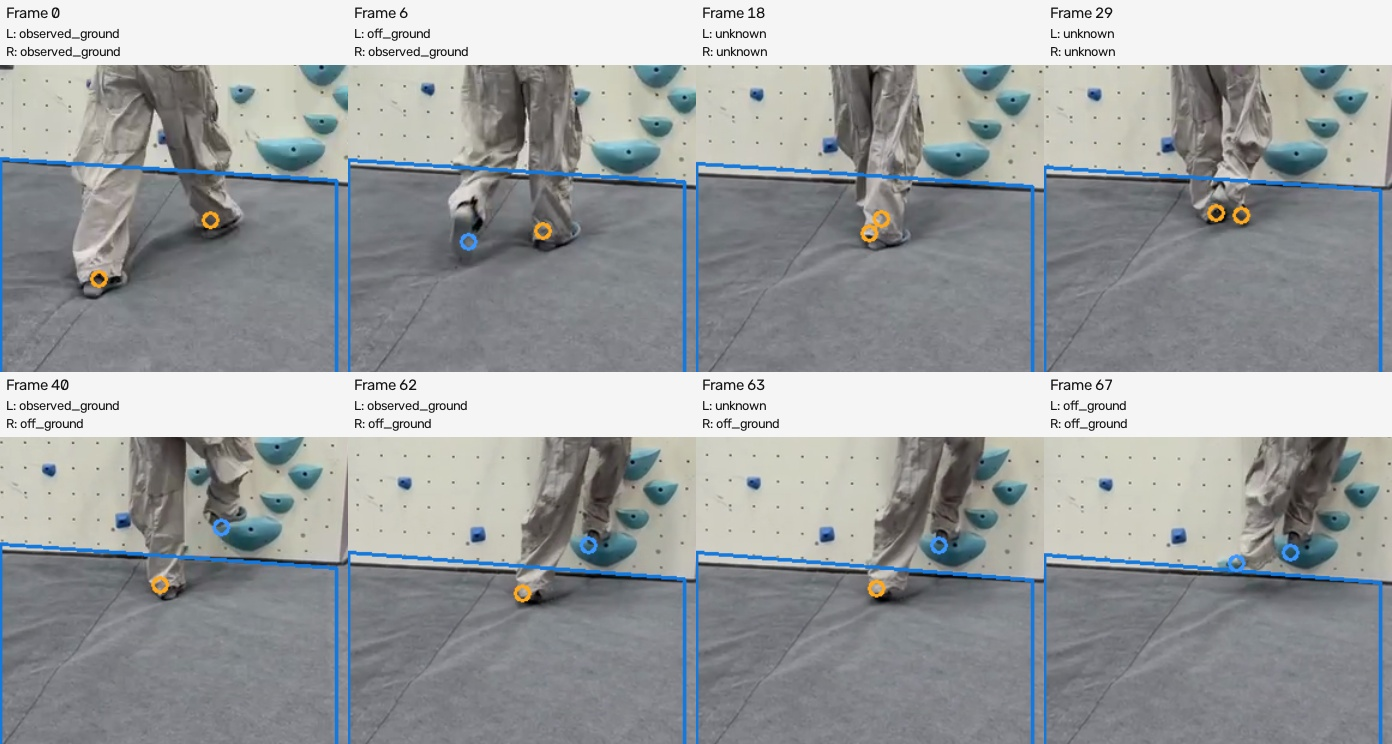

,metric,unit,before,after
0,contact_residual,frames,105.000000,5.000000
1,large_contact_residual,frames,1.000000,0.000000
2,support_balance_failed,frames,65.000000,18.000000
3,support_balance_uncertain,frames,62.000000,96.000000
4,support_margin_low,frames,34.000000,0.000000
5,preunload_failed,frames,26.000000,6.000000
6,preunload_uncertain,frames,20.000000,37.000000
7,preunload_margin_low,frames,0.000000,0.000000
8,departing_load_remaining,frames,14.000000,0.000000
9,rapid_pose_change,frames,0.000000,0.000000


[Open source / ground-support / previous 180 cm no-ground review](outputs/trial1/ground_support/target_180cm_98e558876cb0/review.html)

In [7]:
ground_run = run_trial1_ground_optimization(PROJECT_DIR, **COMMON_SETTINGS, progress=progress)
GROUND_RUN_DIR = Path(ground_run['output_dir'])
print('Ground-support run:', GROUND_RUN_DIR.relative_to(PROJECT_DIR))
print('Final optimizer:', ground_run['optimizer'])
print('Conditional ground limb-frames:', ground_run['ground_contact_limb_frames'],
      '| geometrically eligible ground limb-frames:', ground_run['ground_eligible_limb_frames'])
show_video(ground_run['video_file'])
display(Image(filename=str(GROUND_RUN_DIR / 'ground_evidence.jpg'), width=1100))
display(pd.read_csv(GROUND_RUN_DIR / 'comparison.csv'))
show_review(ground_run, 'Open source / ground-support / previous 180 cm no-ground review')

## 8. Converged Full-Sequence Refinement

Refine every frame with sparse-direct solver steps, explicit inner/outer convergence
checks, exact nominal COM alignment for singleton support, and a soft contact-restoration
term. Labels and audit thresholds stay unchanged. Evaluation limits and stalled,
nonstationary fits are not reported as convergence.

At the saved default configuration, the initialization is the preserved historical
ground-support trajectory identified below. It is **not automatically replaced by the
new Section 7 output**. A changed body, force model or ground schedule creates a fresh
gravity initialization. Its before/after table always compares the actual initialization
with the refined result using the same evidence. See [the refinement method](docs/trial1_refinement.md).

In [8]:
refined_run = run_trial1_refinement(PROJECT_DIR, **COMMON_SETTINGS,
    refinement=REFINEMENT_SETTINGS, progress=progress)
REFINED_RUN_DIR = Path(refined_run['output_dir'])
print('Refined run:', REFINED_RUN_DIR.relative_to(PROJECT_DIR))
print('Initialization mode:', refined_run['initialization'])
print('Preserved previous ground reference:', refined_run['previous_run'])
print('Optimizer:', refined_run['optimizer'])
print('Fresh projected-gradient check:', refined_run['recomputed_projected_gradient'])
show_video(refined_run['video_file'])
display(pd.read_csv(REFINED_RUN_DIR / 'comparison.csv'))
show_counts(refined_run['balance_audit_counts'])
show_counts(refined_run['preunload_frame_counts'])
show_review(refined_run, 'Open source / refined / previous 180 cm ground-support review')

Reused verified Trial1 converged-refinement artifacts.


Refined run: outputs/trial1/refined_support/target_180cm_d7658052307a
Initialization mode: previous_ground_trajectory
Preserved previous ground reference: outputs/trial1/ground_support/target_180cm_bd8c3dc75cd8
Optimizer: {'success': True, 'message': 'Inner stationarity, cost stability, IRLS weight stability and refreshed stationarity satisfied.', 'nfev': 2701, 'cost': 541.7593480709763, 'optimality': 2.489808730591781e-07, 'gradient_definition': 'infinity norm of projected J.T r / max(1, column L2 norm of J)', 'inner_success': True, 'outer_iterations': 3, 'relative_weight_change': 3.7972916895884095e-07, 'max_singleton_com_error_cm': 5.684341886080802e-14}
Fresh projected-gradient check: 2.489808730591781e-07


,metric,unit,before,after
0,contact_residual,frames,5.000000,0.000000
1,large_contact_residual,frames,0.000000,0.000000
2,support_balance_failed,frames,18.000000,0.000000
3,support_balance_uncertain,frames,96.000000,74.000000
4,support_margin_low,frames,0.000000,40.000000
5,preunload_failed,frames,6.000000,0.000000
6,preunload_uncertain,frames,37.000000,43.000000
7,preunload_margin_low,frames,0.000000,0.000000
8,departing_load_remaining,frames,0.000000,0.000000
9,rapid_pose_change,frames,0.000000,0.000000


,status / issue,count
0,uncertain_support,74
1,low_margin,40
2,passes_model_checks,303


,status / issue,count
0,uncertain_support,25
1,not_applicable,337
2,uncertain_timing,18
3,passes_model_checks,37


[Open source / refined / previous 180 cm ground-support review](outputs/trial1/refined_support/target_180cm_d7658052307a/review.html)

## 9. Results Comparison

Compare the three current runs at the same target body, source frames, physics and audit
thresholds. **No-ground versus ground changes the support model**, so it is not an isolated
optimizer comparison. The ground and refinement runs retain the same ground evidence.
The detailed before/after tables in Sections 5, 7 and 8 each use their own actual initialization.

Read contact failures, balance failures, low reserve, uncertainty and maximum gaps together.
Nominal failure can become fragile/low-margin support rather than robust success. Counts
overlap. Inner/outer convergence is explicitly tested only by the refinement solver.

In [9]:
sequence_runs = {'No-ground support': support_run, 'Ground support': ground_run, 'Refined ground': refined_run}
frame_tables = {}
for label, result in sequence_runs.items():
    assert result['body'] == support_run['body'], f'{label}: body mismatch'
    assert result['physics'] == support_run['physics'], f'{label}: physics mismatch'
    assert result['support_audit_settings'] == support_run['support_audit_settings']
    assert result['settings'] == support_run['settings']
    assert (result['frame_count'], result['first_frame'], result['last_frame'], result['fps']) == (417, 0, 416, 30)
    for source, digest in support_run['provenance']['inputs'].items():
        assert result['provenance']['inputs'].get(source) == digest, f'{label}: source/code mismatch: {source}'
    run_dir = Path(result['output_dir'])
    frame_tables[label] = pd.read_csv(run_dir / 'frame_diagnostics.csv')
    with np.load(run_dir / 'trajectory.npz', allow_pickle=False) as trajectory:
        np.testing.assert_array_equal(trajectory['frames'], np.arange(417))
        np.testing.assert_array_equal(trajectory['decoded_labels'], inputs['schedule']['labels'])
assert ground_run['ground_model'] == refined_run['ground_model']
assert ground_run['ground_contact_limb_frames'] == refined_run['ground_contact_limb_frames']

rows = []
metrics = [
    ('Contact failures', 'contact_residual'), ('Nominal balance failures', 'support_balance_failed'),
    ('Low support reserve', 'support_margin_low'), ('Uncertain balance', 'support_balance_uncertain'),
    ('Pre-unload failures', 'preunload_failed'), ('Uncertain pre-unload', 'preunload_uncertain'),
    ('Departing load remaining', 'departing_load_remaining'), ('Rapid pose changes', 'rapid_pose_change'),
    ('Optimizer-unconverged frames', 'optimizer_unconverged'),
]
for label, key in metrics:
    rows.append({'metric': label, 'unit': 'frames',
                 **{name: result['flag_counts'][key] for name, result in sequence_runs.items()}})
for label, key, unit in [('Maximum contact gap', 'max_contact_error_cm', 'cm'),
                         ('Maximum hip step', 'hip_step_cm', 'cm/frame'),
                         ('Maximum angle step', 'angle_step_deg', 'degrees/frame')]:
    rows.append({'metric': label, 'unit': unit,
                 **{name: frames[key].max() for name, frames in frame_tables.items()}})
rows.append({'metric': 'Final solver success flag', 'unit': 'boolean',
             **{name: result['optimizer']['success'] for name, result in sequence_runs.items()}})
comparison_table = pd.DataFrame(rows)
display(comparison_table)
for label, result in sequence_runs.items():
    path = Path(result['video_file']).relative_to(PROJECT_DIR).as_posix()
    display(Markdown(f'**{label}, {TARGET_HEIGHT_CM:g} cm, frames 0–416:** [Open video]({path})'))

,metric,unit,No-ground support,Ground support,Refined ground
0,Contact failures,frames,1,5,0
1,Nominal balance failures,frames,49,18,0
2,Low support reserve,frames,0,0,40
3,Uncertain balance,frames,65,96,74
4,Pre-unload failures,frames,0,6,0
5,Uncertain pre-unload,frames,28,37,43
6,Departing load remaining,frames,0,0,0
7,Rapid pose changes,frames,0,0,0
8,Optimizer-unconverged frames,frames,417,417,0
9,Maximum contact gap,cm,0.108576,0.175493,0.080104


**No-ground support, 180 cm, frames 0–416:** [Open video](outputs/trial1/support_optimized/target_180cm_b55939aa0a8b/trial1_support_optimized_180cm_full_sequence.mp4)

**Ground support, 180 cm, frames 0–416:** [Open video](outputs/trial1/ground_support/target_180cm_98e558876cb0/trial1_support_optimized_180cm_full_sequence.mp4)

**Refined ground, 180 cm, frames 0–416:** [Open video](outputs/trial1/refined_support/target_180cm_d7658052307a/trial1_support_optimized_180cm_full_sequence.mp4)

## 10. Failure Review & Remaining Uncertainty

Inspect problem intervals, ground departures and solver termination. Exact singleton COM
alignment can satisfy nominal equilibrium while failing the unchanged ±2 cm robustness
test. Low reserve and uncertain release timing remain warnings.

Candidate load on a departing limb and whether the remaining supports can carry the fixed
pose are different checks. No future support is borrowed. Uniform image scale, image-up
gravity, approximate sole geometry and contact uncertainty remain; inertia, slipping,
collision, depth, foot rotation, grip strength and alternative-beta planning are not recovered.

No-ground support | optimizer: {'success': False, 'message': 'The maximum number of function evaluations is exceeded.', 'nfev': 800, 'cost': 664.0155194110476, 'optimality': 167.42206062327918}


,frame,max_contact_error_cm,balance_audit_status,unload_audit_status,issues
241,241,0.108576,passes_model_checks,not_applicable,contact_residual;low_contact_confidence;low_po...
240,240,0.088217,passes_model_checks,uncertain_timing,low_contact_confidence;low_pose_visibility;opt...
283,283,0.077679,uncertain_support,uncertain_support,unresolved_foot_support;low_contact_confidence...
282,282,0.070884,uncertain_support,uncertain_support,unresolved_foot_support;low_contact_confidence...
242,242,0.016631,passes_model_checks,not_applicable,low_contact_confidence;low_pose_visibility;opt...
239,239,0.016074,passes_model_checks,uncertain_timing,low_contact_confidence;low_pose_visibility;opt...


,issue,start_frame,end_frame,start_sec,end_exclusive_sec
4,optimizer_unconverged,0,416,0.000000,13.900000
5,support_balance_failed,0,48,0.000000,1.633333
40,contact_residual,241,241,8.033333,8.066667


Ground support | optimizer: {'success': False, 'message': 'The maximum number of function evaluations is exceeded.', 'nfev': 800, 'cost': 637.9997793904038, 'optimality': 285.71998049294}


,frame,max_contact_error_cm,balance_audit_status,unload_audit_status,issues
58,58,0.175493,passes_model_checks,uncertain_timing,contact_residual;low_contact_confidence;low_po...
57,57,0.167624,passes_model_checks,uncertain_timing,contact_residual;low_contact_confidence;low_po...
54,54,0.119251,passes_model_checks,not_applicable,contact_residual;low_contact_confidence;low_po...
61,61,0.110129,passes_model_checks,uncertain_timing,contact_residual;low_pose_visibility;optimizer...
241,241,0.101777,passes_model_checks,not_applicable,contact_residual;low_contact_confidence;low_po...
55,55,0.099018,passes_model_checks,not_applicable,low_pose_visibility;optimizer_unconverged;unif...


,issue,start_frame,end_frame,start_sec,end_exclusive_sec
6,optimizer_unconverged,0,416,0.000000,13.900000
13,preunload_failed,12,17,0.400000,0.600000
17,support_balance_failed,18,35,0.600000,1.200000
23,contact_residual,54,54,1.800000,1.833333
28,contact_residual,57,58,1.900000,1.966667
31,contact_residual,61,61,2.033333,2.066667
58,contact_residual,241,241,8.033333,8.066667


... (4 outputs left out)

,frame,balance_audit_status,eligible_margin,eligible_worst_margin,issues
12,12,low_margin,0.0,NaN,unresolved_foot_support;low_contact_confidence...
13,13,low_margin,0.5,NaN,unresolved_foot_support;low_contact_confidence...
14,14,low_margin,0.0,NaN,unresolved_foot_support;low_contact_confidence...
15,15,low_margin,0.0,NaN,unresolved_foot_support;low_contact_confidence...
16,16,low_margin,0.5,NaN,unresolved_foot_support;low_contact_confidence...
17,17,low_margin,0.5,NaN,unresolved_foot_support;low_contact_confidence...
18,18,low_margin,0.5,NaN,unresolved_foot_support;low_contact_confidence...
19,19,low_margin,0.5,NaN,unresolved_foot_support;low_pose_visibility;su...
20,20,low_margin,0.5,NaN,unresolved_foot_support;low_pose_visibility;su...
21,21,low_margin,0.5,NaN,unresolved_foot_support;low_pose_visibility;su...


,event_id,release_index,release_frame,moving_indices,moving_limbs,from_labels,to_labels,timing_uncertain,timing_reason
0,R001,3,3,[2],left_foot,ground_left_001,free,True,ground_observation_ends_boundary_uncertain
1,R002,18,18,[3],right_foot,ground_right_001,free,True,ground_observation_ends_boundary_uncertain
2,R003,63,63,[2],left_foot,ground_left_002,free,True,ground_observation_ends_boundary_uncertain


,event_id,frame,release_frame,moving_limbs,status,timing_reason,eligible_margin,conditional_margin
2,R001,2,3,left_foot,uncertain_support,ground_observation_ends_boundary_uncertain,NaN,0.666667
8,R002,17,18,right_foot,uncertain_timing,ground_observation_ends_boundary_uncertain,0.500000,0.500000
14,R003,62,63,left_foot,uncertain_timing,ground_observation_ends_boundary_uncertain,0.666667,0.666667
20,R004,75,76,right_hand,passes_model_checks,predicted_first_free_frame,0.500000,0.500000
26,R005,112,113,left_hand,passes_model_checks,predicted_first_free_frame,0.666667,0.666667
32,R006,152,153,right_foot,passes_model_checks,predicted_first_free_frame,0.666667,0.666667
38,R007,179,180,left_foot,passes_model_checks,predicted_first_free_frame,0.666667,0.666667
44,R008,210,211,right_hand,passes_model_checks,predicted_first_free_frame,0.666667,0.666667
50,R009,240,241,left_hand,uncertain_timing,direct_hold_change,0.666667,0.666667
56,R010,265,266,right_foot,uncertain_support,predicted_first_free_frame,NaN,0.666667


,frame,index,kind,group,event_id,nominal_com_x_cm,limbs,status,robustness
37,12,12,unloading,conditional,R002,224.728109,"[0, 1]",exact_nominal_singleton,Not robust to nonzero COM perturbation.
38,13,13,unloading,eligible,R002,224.728109,"[0, 1]",exact_nominal_singleton,Not robust to nonzero COM perturbation.
39,14,14,unloading,conditional,R002,224.728109,"[0, 1]",exact_nominal_singleton,Not robust to nonzero COM perturbation.
40,15,15,unloading,conditional,R002,224.728109,"[0, 1]",exact_nominal_singleton,Not robust to nonzero COM perturbation.
41,16,16,unloading,eligible,R002,224.728109,"[0, 1]",exact_nominal_singleton,Not robust to nonzero COM perturbation.
42,17,17,unloading,eligible,R002,224.728109,"[0, 1]",exact_nominal_singleton,Not robust to nonzero COM perturbation.


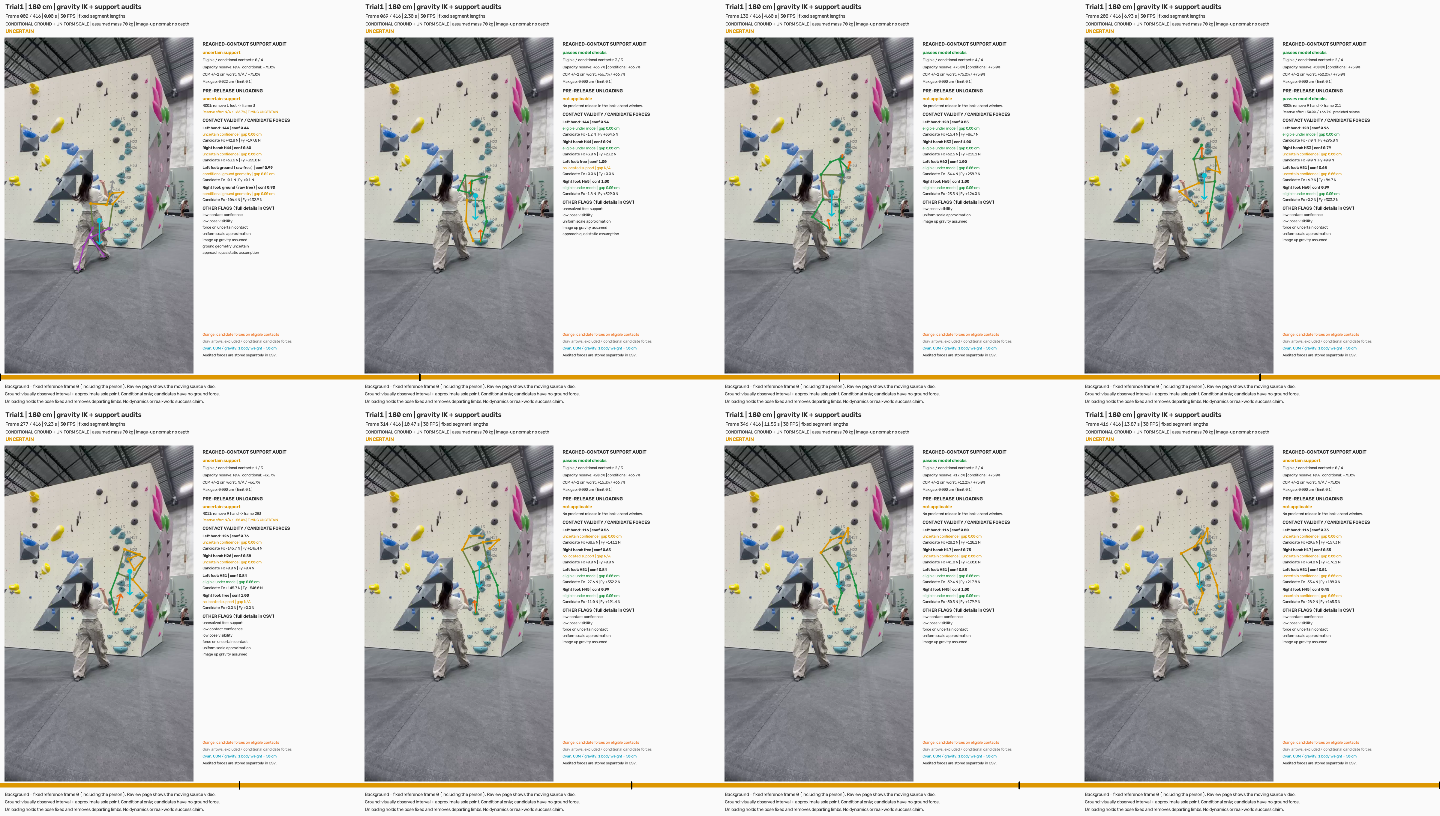

In [10]:
for label, result in sequence_runs.items():
    run_dir = Path(result['output_dir'])
    print(label, '| optimizer:', result['optimizer'])
    frames = frame_tables[label]
    display(frames.nlargest(6, 'max_contact_error_cm')[
        ['frame', 'max_contact_error_cm', 'balance_audit_status', 'unload_audit_status', 'issues']])
    intervals = pd.read_csv(run_dir / 'issue_intervals.csv')
    display(intervals[intervals['issue'].isin([
        'contact_residual', 'support_balance_failed', 'support_margin_low',
        'preunload_failed', 'optimizer_unconverged'])])

refined_frames = frame_tables['Refined ground']
print('Remaining low-margin frames:', int(refined_frames['support_margin_low'].sum()))
display(refined_frames[refined_frames['support_margin_low']][
    ['frame', 'balance_audit_status', 'eligible_margin', 'eligible_worst_margin', 'issues']].head(12))
events = pd.read_csv(REFINED_RUN_DIR / 'release_events.csv')
display(events[events['from_labels'].str.contains('ground_', na=False)])
unload = pd.read_csv(REFINED_RUN_DIR / 'preunload_checks.csv')
if not unload.empty:
    display(unload.groupby('event_id', sort=False).tail(1)[
        ['event_id', 'frame', 'release_frame', 'moving_limbs', 'status', 'timing_reason',
         'eligible_margin', 'conditional_margin']])
singletons = pd.read_csv(REFINED_RUN_DIR / 'singleton_com_constraints.csv')
display(singletons[singletons['kind'] == 'unloading'])
display(Image(filename=str(REFINED_RUN_DIR / 'storyboard.png'), width=1100))

## 11. Saved Outputs & Reproducibility

Results are stored in separate, content-addressed run directories. Videos use repository-
relative file references rather than embedded copies. Keep the complete repository layout.
The table below identifies this execution's artifacts; old results stay in their original locations.

**Do not delete historical result directories just because their notebook was merged.**
The current ground/refinement pipelines read preserved summaries/trajectories, and their
review pages reference prior videos. The former standalone notebook entry points have been
consolidated here; implementation modules, CLI scripts, input caches, annotations and result
directories are still dependencies. No cleanup is performed by this notebook.

In [11]:
output_rows = []
for label, result in sequence_runs.items():
    run_dir = Path(result['output_dir'])
    for filename in ['summary.json', 'trajectory.npz', 'comparison.csv', 'frame_diagnostics.csv',
                     'limb_diagnostics.csv', 'issue_intervals.csv', 'review.html']:
        output_rows.append({'stage': label, 'artifact': filename,
                            'path': (run_dir / filename).relative_to(PROJECT_DIR).as_posix()})
    for filename, digest in result['output_sha256'].items():
        assert file_sha256(run_dir / filename) == digest, f'Output integrity failure: {filename}'
    prior = result['provenance'].get('baseline_summary')
    if prior:
        assert file_sha256(PROJECT_DIR / prior) == result['provenance']['baseline_summary_sha256']
        output_rows.append({'stage': label, 'artifact': 'Preserved dependency', 'path': prior})
for filename in ['convergence.json', 'solver_history.csv', 'singleton_com_constraints.csv', 'ground_evidence.csv']:
    output_rows.append({'stage': 'Refined ground', 'artifact': filename,
                        'path': (REFINED_RUN_DIR / filename).relative_to(PROJECT_DIR).as_posix()})
output_index = pd.DataFrame(output_rows)
display(output_index)
convergence = json.loads((REFINED_RUN_DIR / 'convergence.json').read_text())
print('Refinement convergence:', convergence['optimizer'])
print('Independent refreshed gradient:', convergence['recomputed_refreshed_projected_gradient'])
print('All output hashes checked. Beta_Translator.ipynb and saved source evidence are unchanged.')

,stage,artifact,path
0,No-ground support,summary.json,outputs/trial1/support_optimized/target_180cm_...
1,No-ground support,trajectory.npz,outputs/trial1/support_optimized/target_180cm_...
2,No-ground support,comparison.csv,outputs/trial1/support_optimized/target_180cm_...
3,No-ground support,frame_diagnostics.csv,outputs/trial1/support_optimized/target_180cm_...
4,No-ground support,limb_diagnostics.csv,outputs/trial1/support_optimized/target_180cm_...
5,No-ground support,issue_intervals.csv,outputs/trial1/support_optimized/target_180cm_...
6,No-ground support,review.html,outputs/trial1/support_optimized/target_180cm_...
7,Ground support,summary.json,outputs/trial1/ground_support/target_180cm_98e...
8,Ground support,trajectory.npz,outputs/trial1/ground_support/target_180cm_98e...
9,Ground support,comparison.csv,outputs/trial1/ground_support/target_180cm_98e...


Refinement convergence: {'success': True, 'message': 'Inner stationarity, cost stability, IRLS weight stability and refreshed stationarity satisfied.', 'nfev': 2701, 'cost': 541.7593480709763, 'optimality': 2.489808730591781e-07, 'gradient_definition': 'infinity norm of projected J.T r / max(1, column L2 norm of J)', 'inner_success': True, 'outer_iterations': 3, 'relative_weight_change': 3.7972916895884095e-07, 'max_singleton_com_error_cm': 5.684341886080802e-14}
Independent refreshed gradient: 2.489808730591781e-07
All output hashes checked. Beta_Translator.ipynb and saved source evidence are unchanged.


## 12. Technique Candidates, Comparison & Selected Plan

This experiment generates whole-sequence alternatives inspired by teaching principles:
**weight shift → leg-drive preference → non-contact flagging preference → optional straight-arm / upper-limb load preferences**.
The arrow describes an ablation sequence, not a compulsory execution order. Combined candidates
are evaluated as well. See the English technique table in [Beta Translator, Section 8D](Beta_Translator.ipynb)
and the [method/results guide](docs/trial1_techniques.md).

All candidates keep the same body, contacts, timing, ground evidence and audit thresholds.
Every candidate is jointly fitted across all **417 native frames**; local winners are not joined.
Approach poses before frame 103 and the first/last two poses remain fixed to the preceding result.
The video shows one selected complete plan, with intended stages and numerical reasons.

The same independent force-allocation LP evaluates every candidate. Its hand-load result is a
**conditional lower bound**, not measured effort. A near-zero bound cannot demonstrate effortless
climbing. Source motion observations are proposals for expert review; free-foot frames do not
receive a confirmed flagging label. The Way Up contact network remains unchanged.


In [2]:
from IPython.display import FileLink
from beta_translator.trial1_technique_pipeline import run_trial1_techniques, BASELINE

TECHNIQUE_BASELINE_DIR = Path(globals().get('REFINED_RUN_DIR', PROJECT_DIR / BASELINE))
technique_baseline = json.loads((TECHNIQUE_BASELINE_DIR / 'summary.json').read_text())
assert technique_baseline['body'] == dict(height_cm=float(TARGET_HEIGHT_CM), ratios=TARGET_RATIOS), 'Run Section 8 for this body before Section 12.'
assert technique_baseline['physics']['mass_kg'] == TARGET_MASS_KG and technique_baseline['physics']['foot_friction'] == FOOT_FRICTION, 'Run Section 8 for these physics assumptions.'
expected_force_limit = TARGET_MASS_KG * 9.81 if MAX_FORCE_N is None else MAX_FORCE_N
assert np.isclose(technique_baseline['physics']['max_force_component_n'], expected_force_limit), 'Run Section 8 for this force limit.'
technique_plan = run_trial1_techniques(
    PROJECT_DIR, height_cm=TARGET_HEIGHT_CM,
    baseline_dir=TECHNIQUE_BASELINE_DIR.relative_to(PROJECT_DIR),
)
TECHNIQUE_RUN_DIR = Path(technique_plan['output_dir'])
print('Selected complete candidate:', technique_plan['selected_profile'])
print('All frames retain geometry uncertainty; no physical or fatigue validation.')
comparison = pd.read_csv(TECHNIQUE_RUN_DIR / 'candidate_comparison.csv')
display(comparison[['rank', 'profile', 'converged', 'contact_residual', 'support_balance_failed',
                    'preunload_failed', 'hand_integral_l1_bw_s', 'hand_peak_l1_bw',
                    'arm_moment_integral_bw_cm_s', 'zero_hand_lower_bound_frames', 'selection_reason']])


Selected complete candidate: weight_shift
All frames retain geometry uncertainty; no physical or fatigue validation.


,rank,profile,converged,contact_residual,support_balance_failed,preunload_failed,hand_integral_l1_bw_s,hand_peak_l1_bw,arm_moment_integral_bw_cm_s,zero_hand_lower_bound_frames,selection_reason
0,1,weight_shift,True,0,0,0,0.959144,1.0,53.195953,257,Selected complete trajectory under feasibility...
1,2,flag_assist,True,0,0,0,0.961845,1.0,53.567035,257,Not selected: first ranking difference is arm-...
2,3,leg_drive,True,0,0,0,0.960797,1.0,53.581448,257,Not selected: first ranking difference is arm-...
3,4,arm_economy,True,0,0,0,0.958902,1.0,53.722853,256,Not selected: first ranking difference is arm-...
4,5,combined,True,0,0,0,0.959711,1.0,53.686863,256,Not selected: first ranking difference is arm-...
5,6,preserved_baseline,True,0,0,0,1.081099,1.0,55.859631,249,Not selected: first ranking difference is hand...
6,7,control,True,0,0,0,1.081099,1.0,55.859631,249,Not selected: first ranking difference is hand...


/Users/ziwei/Documents/ChatGPT/CIS5810/experiments/trial1-techniques-ast3nvfz/repo/outputs/trial1/technique_plans/target_180cm_cf107c3b5dfe/review.html

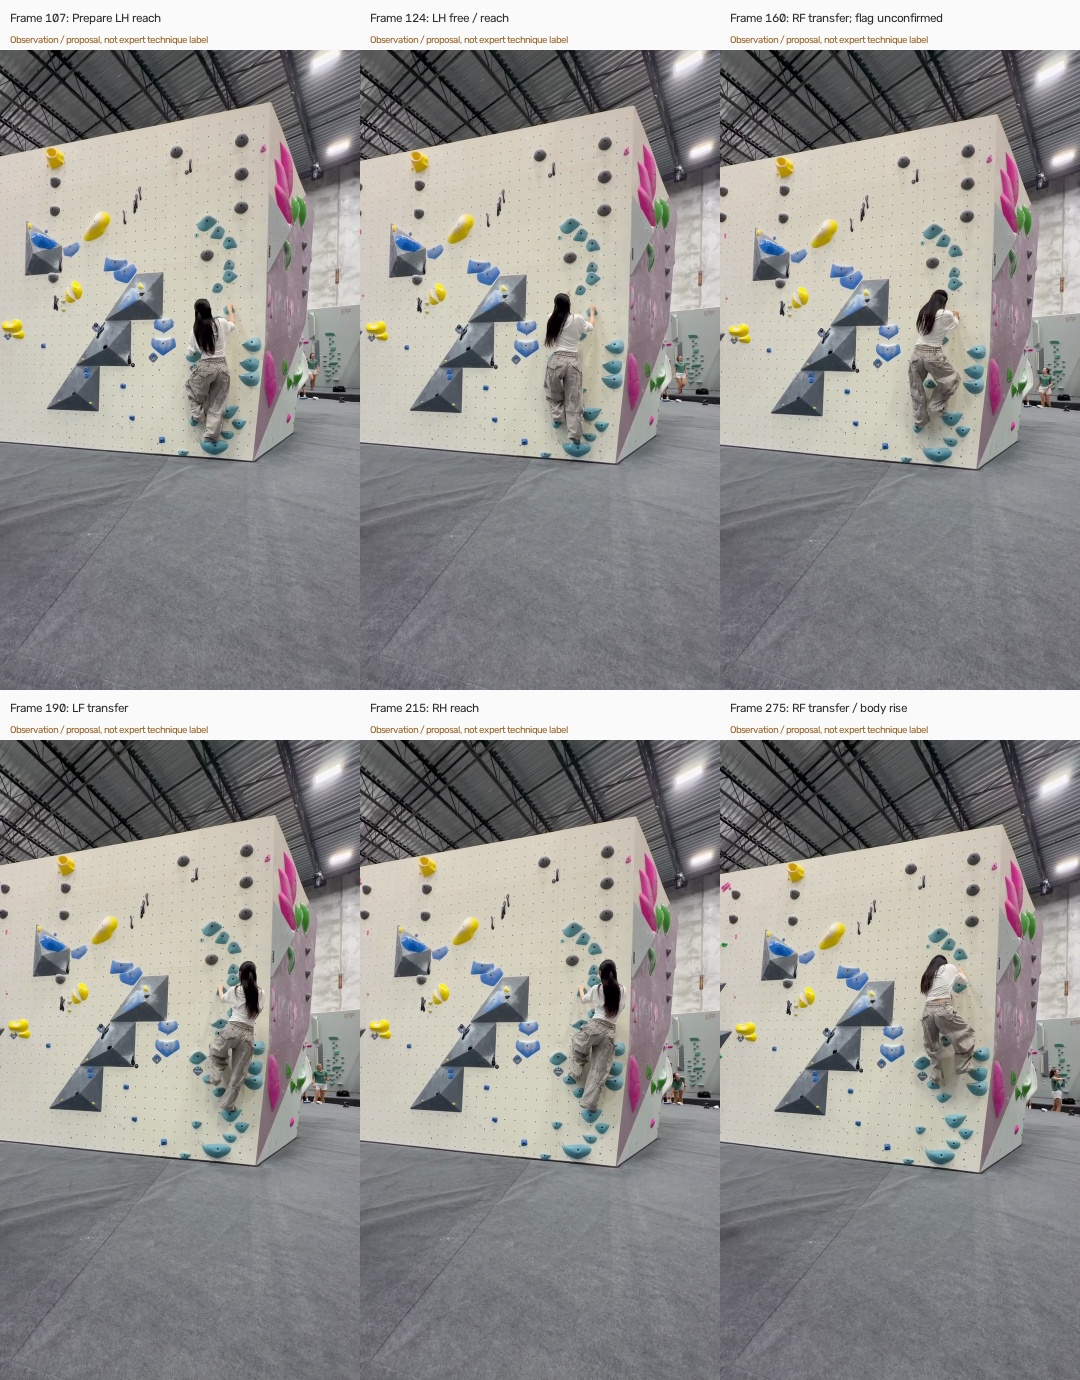

,event_id,moving_limb,release_frame,arrival_frame,from_hold,to_hold,observed_hip_dx_projected_cm,observed_hip_dy_projected_cm,observation,review_status
0,T01,left_foot,3,36,ground_left_001,ground_left_002,31.972879,16.125063,Foot transfer; possible subsequent body rise,needs_expert_review
1,T02,right_foot,18,49,ground_right_001,H65,34.133133,7.780201,Foot transfer; possible subsequent body rise,needs_expert_review
2,T03,left_foot,63,83,ground_left_002,H62,19.029387,20.230512,Foot transfer; possible subsequent body rise,needs_expert_review
3,T04,right_hand,76,103,H44,H33,-20.725857,11.914944,Reach with body repositioning,needs_expert_review
4,T05,left_hand,113,136,H44,H28,-12.115323,7.986893,Reach with body repositioning,needs_expert_review
5,T06,right_foot,153,173,H65,H60,33.242700,32.879300,Foot transfer; possible subsequent body rise,needs_expert_review
6,T07,left_foot,180,206,H62,H51,21.860347,20.082086,Foot transfer; possible subsequent body rise,needs_expert_review
7,T08,right_hand,211,226,H33,H26,-4.396656,0.067364,Reach with body repositioning,needs_expert_review
8,T09,right_foot,266,286,H60,H45,-0.758412,40.262707,Foot transfer; possible subsequent body rise,needs_expert_review
9,T10,left_hand,288,305,H26,H16,5.129320,8.604280,Reach with body repositioning,needs_expert_review


These are image-plane observations under the existing scale assumption. Technique labels remain blank for expert review.


In [3]:
display(Video(filename=str((TECHNIQUE_RUN_DIR / 'selected_plan.mp4').relative_to(PROJECT_DIR)), embed=False, width=1100))
display(FileLink(str((TECHNIQUE_RUN_DIR / 'review.html').relative_to(PROJECT_DIR)), result_html_prefix='Selected plan, phase reasons and candidate comparison: '))
display(Image(filename=str(TECHNIQUE_RUN_DIR / 'source_evidence.jpg'), width=900))
review_queue = pd.read_csv(TECHNIQUE_RUN_DIR / 'technique_review_queue.csv')
display(review_queue[['event_id', 'moving_limb', 'release_frame', 'arrival_frame',
                     'from_hold', 'to_hold', 'observed_hip_dx_projected_cm',
                     'observed_hip_dy_projected_cm', 'observation', 'review_status']])
print('These are image-plane observations under the existing scale assumption. Technique labels remain blank for expert review.')
